# Face accessories: dataset and human-review analysis
## 1. Setup and paths

In [1]:
import sys
import subprocess
import importlib.metadata
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
try:
    for package in ['pandas','numpy','matplotlib','Pillow']:
        importlib.metadata.version(package)
    needs_install = tuple(map(int,importlib.metadata.version('matplotlib').split('.')[:2])) < (3,9)
except importlib.metadata.PackageNotFoundError:
    needs_install = True
if needs_install:
    subprocess.check_call([sys.executable,'-m','pip','install','pandas>=2','numpy>=1.24','matplotlib>=3.9','Pillow>=10'])
print('Colab: configure the shared project path below.' if IN_COLAB else 'Local notebook mode.')

Mounted at /content/drive
Colab: configure the shared project path below.


In [2]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import math
import uuid
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown


# Set these explicitly only if your folder layout differs.
PROJECT_DIR = Path('/content/drive/MyDrive/Frugal AI Project') if IN_COLAB else None
# In Colab, edit PROJECT_DIR to the shared folder (or its shortcut in My Drive).
TEAM_DIR = (
    PROJECT_DIR
    / 'Human-review'
    / 'human_review'
    / 'team_results'
)     # Defaults to PROJECT_DIR / 'human_review/team_results' on Drive.
REVIEW_CSV = None   # e.g. Path(r"C:\data\human_review.csv")
REVIEW_MODE = 'team'  # 'team' combines all slots and baseline; 'individual' selects REVIEWER.
REVIEWER = None     # Used in individual mode; None selects the reviewer with most rows.
SEED = 60

cwd = Path.cwd().resolve()
if PROJECT_DIR is None:
    for root in [cwd, *list(cwd.parents)[:2]]:
        candidates = list(root.glob('sampled_dataset.csv')) + list(root.glob('*/sampled_dataset.csv')) + list(root.glob('*/*/sampled_dataset.csv'))
        candidates = sorted(set(candidates))
        if len(candidates) == 1:
            PROJECT_DIR = candidates[0].parent
            break
        if len(candidates) > 1:
            raise ValueError('Multiple samples found. Set PROJECT_DIR explicitly.')
    if PROJECT_DIR is None:
        raise FileNotFoundError('Set PROJECT_DIR to the folder containing sampled_dataset.csv.')
PROJECT_DIR = Path(PROJECT_DIR).resolve()
assert (PROJECT_DIR/'sampled_dataset.csv').is_file(), 'Correct PROJECT_DIR to the shared project folder.'
if TEAM_DIR is None:
    team_candidates = [PROJECT_DIR/'human_review/team_results']
    if not IN_COLAB:
        team_candidates += [root/'human_review/team_results' for root in [cwd,*list(cwd.parents)[:2]]]
    TEAM_DIR = next((p for p in team_candidates if (p/'assignments.csv').is_file()), None)
else:
    TEAM_DIR = Path(TEAM_DIR)
if REVIEW_CSV is None:
    candidates = [root / 'human_review/results/human_review.csv'
                  for root in [cwd, *list(cwd.parents)[:2], PROJECT_DIR, *list(PROJECT_DIR.parents)[:2]]]
    REVIEW_CSV = next((p for p in candidates if p.is_file()), None)
elif REVIEW_CSV is not None:
    REVIEW_CSV = Path(REVIEW_CSV).resolve()
analysis_dir = PROJECT_DIR if IN_COLAB else (cwd if cwd.name == 'analysis' else cwd / 'analysis')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
OUT = analysis_dir / 'analysis_outputs' / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10, 'axes.titleweight': 'bold'})
COLORS = {'original': '#477a91', 'sample': '#226a50', 'mask': '#287b8e', 'cap': '#d49a36',
          'glasses': '#8977b0', 'accept': '#2d8664', 'reject': '#c45751',
          'uncertain': '#d7a447', 'unreviewed': '#dce2e5'}
def finish(name):
    plt.savefig(OUT / (name + '.png'), bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()
def table(frame, name, index=False):
    frame.to_csv(OUT / (name + '.csv'), index=index)
    display(frame)
INPUT_HASHES = {}
def read_metadata(path):
    content = path.read_bytes()
    INPUT_HASHES[str(path)] = hashlib.sha256(content).hexdigest()
    frame = pd.read_csv(io.BytesIO(content), dtype=str).fillna('')
    required = ['HASH', 'ETHNICITY', 'GENDER', 'AGE']
    assert set(required).issubset(frame), f'Missing metadata columns: {path}'
    assert not frame[required].eq('').any().any(), f'Missing metadata values: {path}'
    assert frame.HASH.is_unique, f'Duplicate HASH values: {path}'
    return frame

original = read_metadata(PROJECT_DIR / 'final_dataset.csv')
sample = read_metadata(PROJECT_DIR / 'sampled_dataset.csv')
assert set(sample.HASH) <= set(original.HASH), 'Sample includes IDs outside original metadata.'
assert sample.set_index('HASH').sort_index().equals(original.set_index('HASH').loc[sample.HASH].sort_index()), 'Sample labels differ from original labels.'
DEMOGRAPHICS = ['ETHNICITY', 'GENDER', 'AGE']
ETHNICITIES = sorted(original.ETHNICITY.unique())
GENDERS = sorted(original.GENDER.unique())
AGES = sorted(original.AGE.unique(), key=float)
SOURCE = PROJECT_DIR / 'generated_portraits_hashed_final/generated_portraits_hashed'
ACCESSORY_DIRS = {'mask': PROJECT_DIR / 'generated_masks', 'cap': PROJECT_DIR / 'generated_cap',
                  'glasses': PROJECT_DIR / 'generated_glasses'}
SUFFIXES = {'mask': ['_mask'], 'cap': ['_hat', '_cap'], 'glasses': ['_glasses', '']}
print('Project:', PROJECT_DIR)
print('Human review CSV:', REVIEW_CSV or 'Not found — review section will be skipped')
print('Team results:', TEAM_DIR or 'Not found — using legacy review CSV if available')
print('Figures and tables:', OUT)
print('Analysis time (UTC):', datetime.now(timezone.utc).isoformat(timespec='seconds'))

Project: /content/drive/.shortcut-targets-by-id/1PC3BlA0EHJknESqXxcHrKbm48XgVYJJD/Frugal AI Project
Human review CSV: Not found — review section will be skipped
Team results: /content/drive/MyDrive/Frugal AI Project/Human-review/human_review/team_results
Figures and tables: /content/drive/.shortcut-targets-by-id/1PC3BlA0EHJknESqXxcHrKbm48XgVYJJD/Frugal AI Project/analysis_outputs/20261012T220605Z_c9b49572
Analysis time (UTC): 2026-10-12T22:06:06+00:00


## 2. Original dataset: inventory and metadata quality
`final_dataset.csv` defines the original analysis population. The source image folder may contain
additional files; those are reported separately and are not silently added to the dataset.
Existence checks do not prove that an image is visually valid.

In [3]:
source_files = sorted(p for p in SOURCE.glob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
source_ids = {p.stem for p in source_files}
original['source_exists'] = original.HASH.map(lambda h: (SOURCE / f'{h}.jpg').is_file())
inventory = pd.DataFrame([
    ['Original metadata records', len(original)],
    ['Unique original IDs', original.HASH.nunique()],
    ['Image files in source folder', len(source_files)],
    ['Metadata IDs with expected JPG present', int(original.source_exists.sum())],
    ['Metadata IDs missing expected JPG', int((~original.source_exists).sum())],
    ['Source file IDs absent from original metadata', len(source_ids - set(original.HASH))],
    ['Sampled identities', len(sample)],
], columns=['Measure', 'Count'])
table(inventory, '01_inventory')
missing_originals = original.loc[~original.source_exists, ['HASH']]
missing_originals.to_csv(OUT / 'missing_originals.csv', index=False)

,Measure,Count
0,Original metadata records,9000
1,Unique original IDs,9000
2,Image files in source folder,12393
3,Metadata IDs with expected JPG present,9000
4,Metadata IDs missing expected JPG,0
5,Source file IDs absent from original metadata,3393
6,Sampled identities,720


- **Original metadata records  9000:** Total rows in final_dataset.csv; each row describes one original portrait.

- **Unique original IDs  9000:** Every metadata row has a different portrait ID. There are no duplicate IDs in the CSV.

- **Image files in source folder  12,393:** Total image files physically found in the original-images folder.

- **Metadata IDs with expected JPG present  9000:** Every portrait listed in the CSV has its expected .jpg file available. This confirms the dataset is complete for analysis/generation.

- **Metadata IDs missing expected JPG  0:** No CSV record lacks its required original image.

- **Source file IDs absent from original metadata  3,393:** Extra image files exist in the folder but their IDs are not included in final_dataset.csv. They are not used by the metadata-based analysis or your sample.

- **Sampled identities  720:** Your research subset contains 720 portraits: 30 samples for every race × gender × age-group combination.
Because the images folder contains extra files beyond the 9,000 portraits listed in final_dataset.csv.

Your analysis matched filenames to the 9,000 metadata IDs:

- **9,000** source images match an ID in the CSV and are the valid dataset records.
- **3,393** additional image files have IDs absent from the CSV, so they have no race, gender, or age metadata and are excluded.
- **12,393 = 9,000 + 3,393**.

Your sampled dataset and generated-accessory analysis correctly use only the 9,000 matched records, then the 720 sampled identities.

### Original demographic distributions

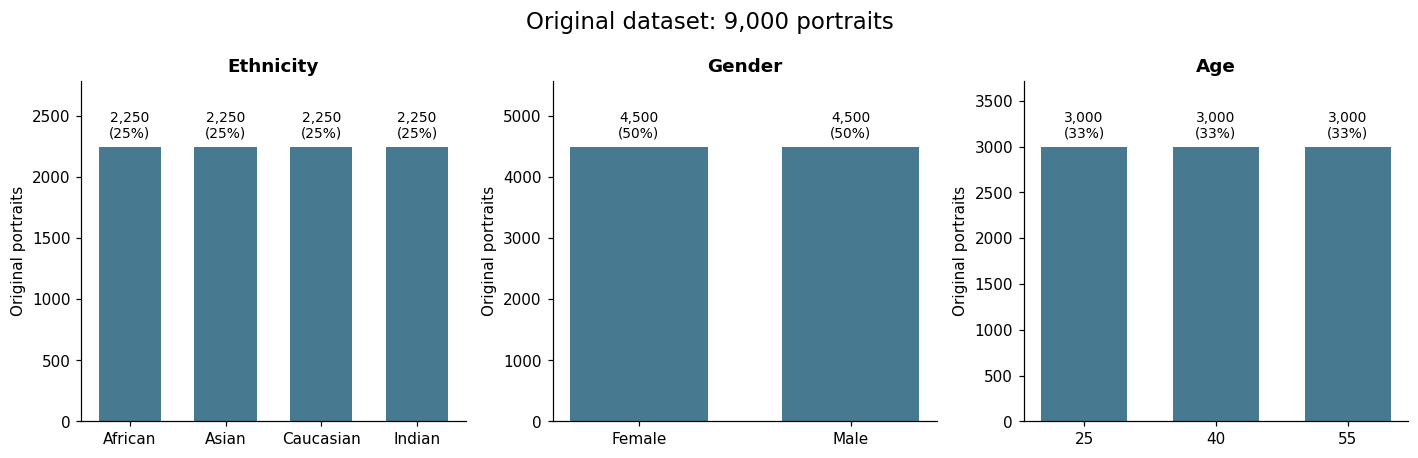

,ETHNICITY,GENDER,AGE,original_n,sample_n,sampling_fraction
0,African,Female,25,375,30,0.08
1,African,Female,40,375,30,0.08
2,African,Female,55,375,30,0.08
3,African,Male,25,375,30,0.08
4,African,Male,40,375,30,0.08
5,African,Male,55,375,30,0.08
6,Asian,Female,25,375,30,0.08
7,Asian,Female,40,375,30,0.08
8,Asian,Female,55,375,30,0.08
9,Asian,Male,25,375,30,0.08


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, column, order in zip(axes, DEMOGRAPHICS, [ETHNICITIES, GENDERS, AGES]):
    counts = original[column].value_counts().reindex(order, fill_value=0)
    bars = ax.bar(counts.index, counts.values, color=COLORS['original'], width=.65)
    ax.bar_label(bars, labels=[f'{n:,}\n({n/len(original):.0%})' for n in counts], padding=4, fontsize=9)
    ax.set(title=column.title(), ylabel='Original portraits', ylim=(0, counts.max()*1.24))
fig.suptitle(f'Original dataset: {len(original):,} portraits', fontsize=15)
fig.tight_layout()
finish('02_original_distributions')

strata = pd.MultiIndex.from_product([ETHNICITIES, GENDERS, AGES], names=DEMOGRAPHICS)
original_cells = original.groupby(DEMOGRAPHICS).size().reindex(strata, fill_value=0)
sample_cells = sample.groupby(DEMOGRAPHICS).size().reindex(strata, fill_value=0)
balance = pd.DataFrame({'original_n': original_cells, 'sample_n': sample_cells})
balance['sampling_fraction'] = balance.sample_n.div(balance.original_n.replace(0, np.nan))
table(balance.reset_index(), '03_demographic_cells')

- **original_n**: Number of available portraits in that demographic group in the full original dataset. Here, each race × gender × age group has **375** images.

- **sample_n**: Number selected from that group for your research sample. You selected **30** images per group.

- **sampling_fraction**: Proportion of the original group included in the sample:  
  sample_n ÷ original_n = 30 ÷ 375 = 0.08
  So each group contributes **8%** of its original images.

This equal sampling keeps the 720-image sample balanced across demographic groups.
4ethnicities * 2genders * 3ages = 24 row
The 24 groups are:
- 4 ethnicities: African, Asian, Caucasian, Indian
- 2 genders: Female, Male
- 3 ages: 25, 40, 55

### Balance across combinations, and original portrait examples

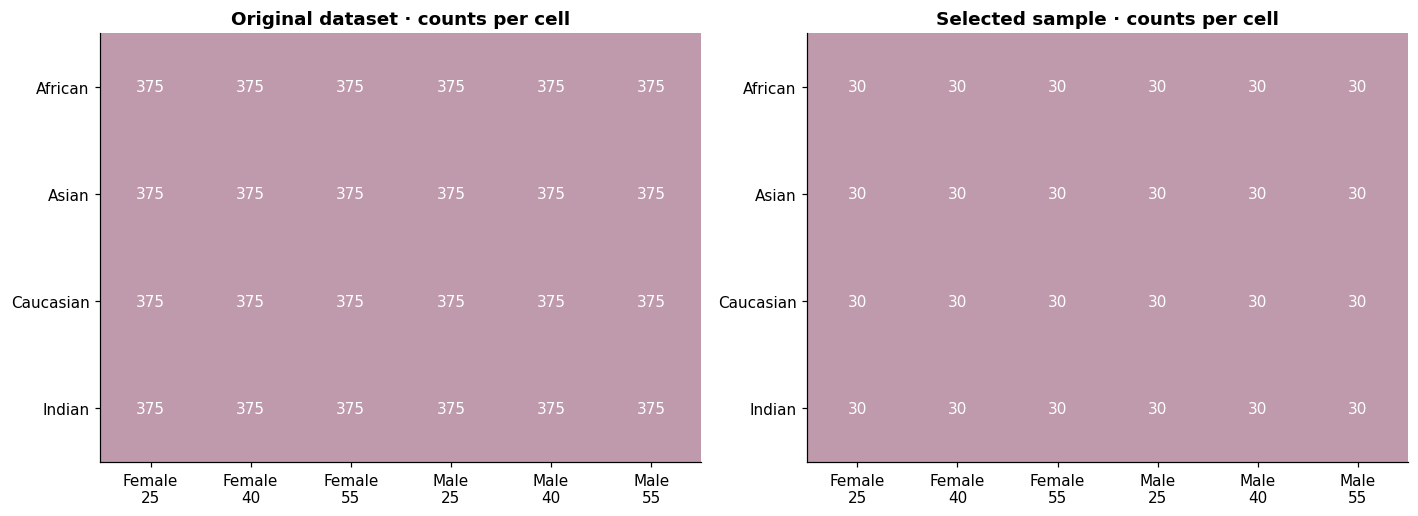

In [5]:
from matplotlib.colors import LinearSegmentedColormap

# Custom colormap: light → #ac7c94
custom_cmap = LinearSegmentedColormap.from_list(
    'custom_pink',
    ['#ffffff', '#ac7c94']
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax, values, title in zip(
    axes,
    [original_cells, sample_cells],
    ['Original dataset', 'Selected sample']
):
    matrix = values.unstack(['GENDER', 'AGE'])

    image = ax.imshow(
        matrix.values,
        cmap=custom_cmap,   # <-- use your color here
        vmin=0,
        vmax=max(1, matrix.values.max() * 1.3),
        aspect='auto'
    )

    ax.set_xticks(
        range(len(matrix.columns)),
        [f'{g}\n{a}' for g, a in matrix.columns]
    )
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title + ' · counts per cell')

    for y in range(len(matrix)):
        for x in range(len(matrix.columns)):
            ax.text(
                x, y,
                str(matrix.iloc[y, x]),
                ha='center',
                va='center',
                color='white'
                if matrix.iloc[y, x] > matrix.values.max() * .7
                else 'black'
            )

fig.tight_layout()
finish('04_original_sample_balance')

This compares the demographic balance of the full dataset with your selected sample.
- Rows are ethnicities: African, Asian, Caucasian, Indian.
- Columns are the six gender-and-age groups:
  Female 25, Female 40, Female 55, Male 25, Male 40, Male 55.
- Each square is one demographic cell: ethnicity × gender × age.
On the left, every cell contains 375 original portraits. So the original dataset is perfectly balanced:
\[
4 x 2 x 3 x 375 = 9{,}000
\]On the right, every cell contains 30 selected portraits. Your sample is also perfectly balanced:
\[
4 x 2 x 3 x 30 = 720
\]The same colour throughout each plot confirms equal counts across all demographic groups. This means later differences in mask, cap, or glasses generation/review results are less likely to be caused by one demographic group having more images than another.

## 3. Sample and generation coverage

Sample size: 720 / 9,000 originals (8.0%)
Demographic cells: 24
All cells have 30 sampled identities: True


,accessory,expected,matched_ids,missing_ids,files_in_folder,extra_ids,duplicate_ids
0,mask,720,720,0,720,0,0
1,cap,720,720,0,720,0,0
2,glasses,720,720,0,720,0,0


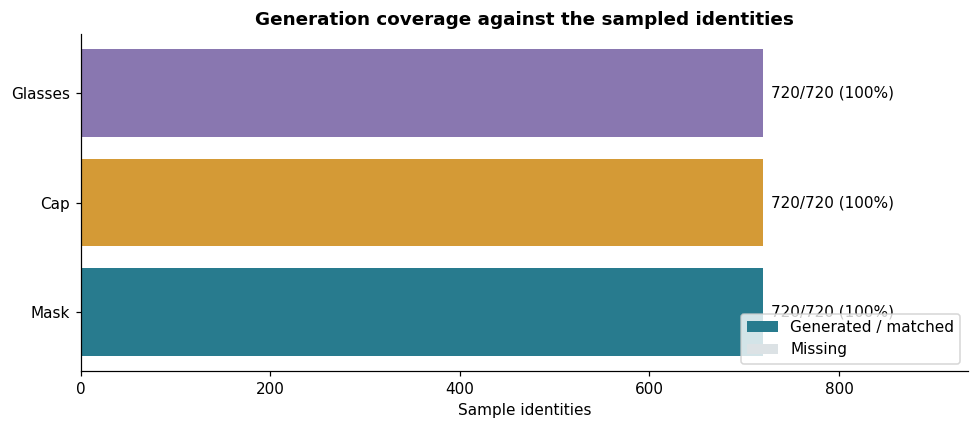

Separate pilot files by version (excluded above): {'original': 8, 'glasses': 8, 'mask': 8, 'cap': 8, 'no_edit': 8}


In [6]:
print(f'Sample size: {len(sample):,} / {len(original):,} originals ({len(sample)/len(original):.1%})')
print('Demographic cells:', len(balance))
print('All cells have 30 sampled identities:', bool(balance.sample_n.eq(30).all()))

manifest_rows, issues, coverage_rows = [], [], []
for accessory, folder in ACCESSORY_DIRS.items():
    paths = sorted(p for p in folder.glob('*') if p.suffix.lower() in {'.png','.jpg','.jpeg'})
    mapped = {}
    for path in paths:
        h = path.stem
        for suffix in SUFFIXES[accessory]:
            if suffix and h.endswith(suffix):
                h = h[:-len(suffix)]
                break
        mapped.setdefault(h, []).append(path)
    matched = set(mapped) & set(sample.HASH)
    for h, paths_for_id in mapped.items():
        if h not in set(sample.HASH):
            issues.append({'accessory': accessory, 'HASH': h, 'issue': 'outside_sample', 'files': '|'.join(map(str,paths_for_id))})
        if len(paths_for_id)>1:
            issues.append({'accessory': accessory, 'HASH': h, 'issue': 'duplicate_output', 'files': '|'.join(map(str,paths_for_id))})
    for row in sample.to_dict('records'):
        paths_for_id = mapped.get(row['HASH'], [])
        manifest_rows.append({**row, 'accessory': accessory, 'exists': bool(paths_for_id),
                              'file_count': len(paths_for_id), 'path': str(paths_for_id[0]) if paths_for_id else ''})
    coverage_rows.append({'accessory': accessory, 'expected':len(sample), 'matched_ids':len(matched),
                          'missing_ids':len(sample)-len(matched), 'files_in_folder':len(paths),
                          'extra_ids':len(set(mapped)-set(sample.HASH)),
                          'duplicate_ids':sum(len(v)>1 for v in mapped.values())})
manifest = pd.DataFrame(manifest_rows)
coverage = pd.DataFrame(coverage_rows)
table(coverage, '06_generation_coverage')
manifest.to_csv(OUT/'generation_manifest.csv',index=False)
pd.DataFrame(issues, columns=['accessory','HASH','issue','files']).to_csv(OUT/'generation_file_issues.csv',index=False)
fig, ax = plt.subplots(figsize=(9,4))
x = np.arange(len(coverage))
ax.barh(x, coverage.matched_ids, color=[COLORS[a] for a in coverage.accessory], label='Generated / matched')
ax.barh(x, coverage.missing_ids, left=coverage.matched_ids, color=COLORS['unreviewed'], label='Missing')
for y,r in enumerate(coverage.itertuples()):
    ax.text(r.expected+8, y, f'{r.matched_ids}/{r.expected} ({r.matched_ids/r.expected:.0%})', va='center')
ax.set_yticks(x, coverage.accessory.str.title())
ax.set(xlabel='Sample identities', title='Generation coverage against the sampled identities', xlim=(0,len(sample)*1.3))
ax.legend(loc='lower right'); fig.tight_layout(); finish('07_generation_coverage')
pilot_dir = PROJECT_DIR/'Evaluation_pilot_8_portraits_40_images'
pilot_counts = Counter(p.stem.split('_',1)[1] for p in pilot_dir.glob('*.png') if '_' in p.stem)
print('Separate pilot files by version (excluded above):', dict(pilot_counts))

A separate pilot folder containing 40 images from 8 selected portraits:
- 8 original: source portraits
- 8 glasses: portraits generated with glasses
- 8 mask: portraits generated with masks
- 8 cap: portraits generated with baseball caps
- 8 no_edit: generated portraits where no accessory was requested
These pilot images are kept separate from the 720-image main sample, so they are excluded from the main coverage and demographic analysis. They are useful for testing generation settings or showing qualitative examples, but should not be mixed into the main experiment unless your team explicitly decides to include them.

### Image dimensions, file sizes, and decoding checks

,version,width,height,format,images
0,cap,512,512,PNG,720
1,glasses,512,512,PNG,720
2,mask,512,512,PNG,720
3,original,256,256,JPEG,720


Files with decoding / access errors: 0


,version,count,median,min,max
0,cap,720,228.0,195.1,285.1
1,glasses,720,245.8,211.7,316.8
2,mask,720,250.3,213.3,321.8
3,original,720,15.6,12.4,22.3


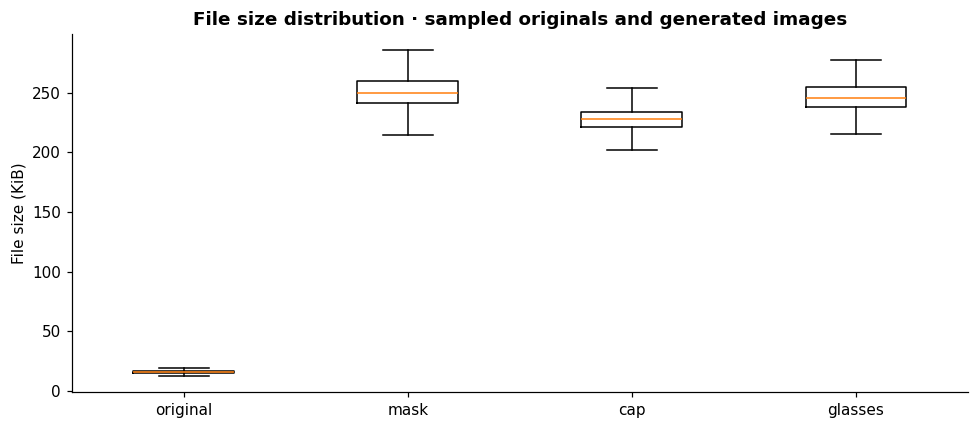

In [7]:
scan_records = [{'HASH': h, 'version': 'original', 'path':str(SOURCE/f'{h}.jpg')} for h in sample.HASH]
scan_records += [{'HASH':r.HASH,'version':r.accessory,'path':r.path} for r in manifest[manifest.exists].itertuples()]
image_rows = []
for item in scan_records:
    result = dict(item)
    try:
        path = Path(item['path'])
        result['size_kib'] = path.stat().st_size/1024
        with Image.open(path) as im:
            im.load()
            result.update(width=im.width, height=im.height, mode=im.mode, format=im.format, error='')
    except Exception as error:
        result['error'] = str(error)
    image_rows.append(result)
image_info = pd.DataFrame(image_rows)
image_info.to_csv(OUT/'image_integrity.csv',index=False)
valid_images = image_info[image_info.error.eq('')].copy()
table(valid_images.groupby(['version','width','height','format']).size().rename('images').reset_index(), '08_image_dimensions')
print('Files with decoding / access errors:', int(image_info.error.ne('').sum()))
if image_info.error.ne('').any(): display(image_info[image_info.error.ne('')])
size_summary = valid_images.groupby('version').size_kib.agg(['count','median','min','max']).round(1)
table(size_summary.reset_index(), '09_file_size_summary')
fig, ax = plt.subplots(figsize=(9,4))
versions = [v for v in ['original','mask','cap','glasses'] if v in set(valid_images.version)]
if versions:
    ax.boxplot([valid_images.loc[valid_images.version.eq(v),'size_kib'] for v in versions], tick_labels=versions, showfliers=False)
ax.set(ylabel='File size (KiB)',title='File size distribution · sampled originals and generated images')
fig.tight_layout(); finish('10_file_sizes')

### Side-by-side generated examples


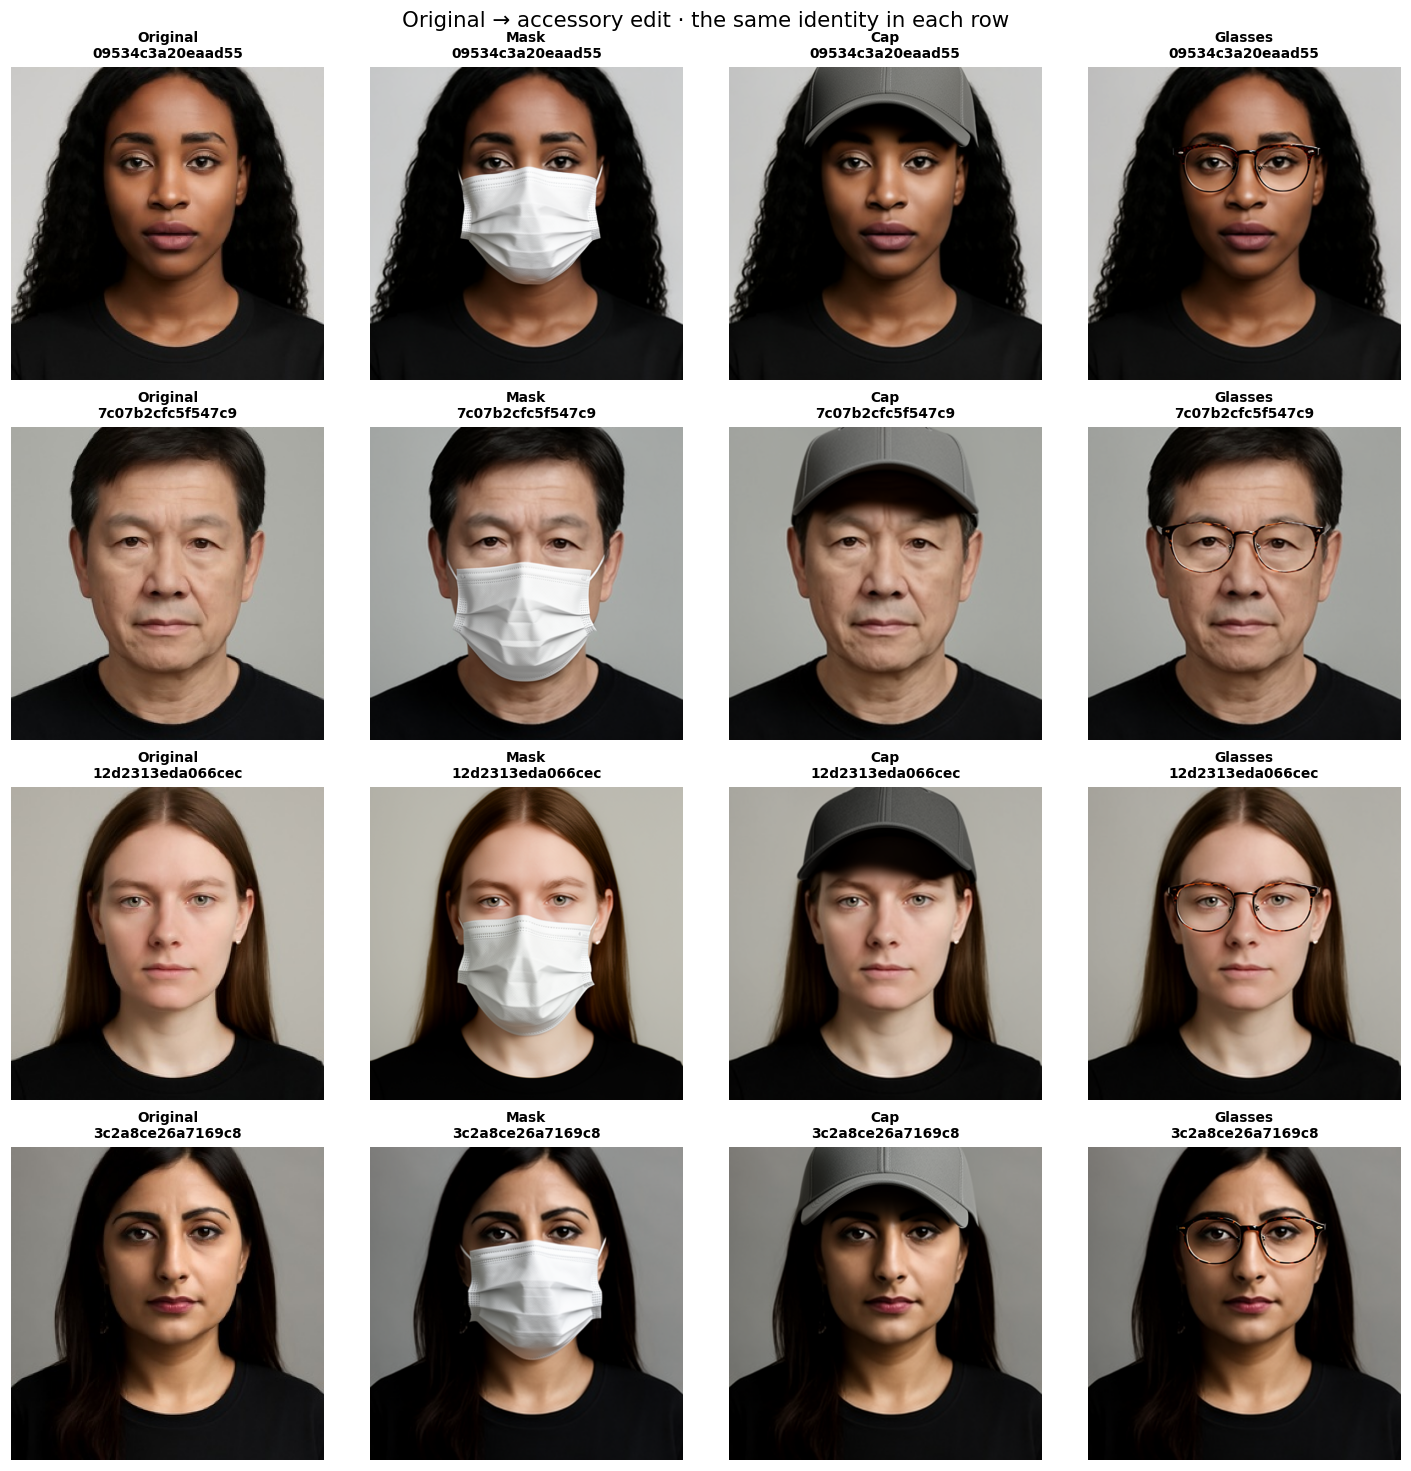

In [8]:
pair_examples = sample.groupby('ETHNICITY',group_keys=False).sample(n=1,random_state=SEED).sort_values('ETHNICITY')
available_accessories = [a for a in ['mask','cap','glasses'] if manifest.loc[manifest.accessory.eq(a),'exists'].any()]
columns = ['original'] + available_accessories
fig, axes = plt.subplots(len(pair_examples),len(columns),figsize=(3.3*len(columns),3.4*len(pair_examples)),squeeze=False)
lookup = manifest.set_index(['HASH','accessory'])
for y,row in enumerate(pair_examples.itertuples()):
    for x,version in enumerate(columns):
        ax=axes[y,x]
        path = SOURCE/f'{row.HASH}.jpg' if version=='original' else Path(lookup.loc[(row.HASH,version),'path'])
        if path.is_file():
            with Image.open(path) as im: ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        else: ax.text(.5,.5,'Output missing',ha='center')
        ax.set_title(f'{version.title()}\n{row.HASH}', fontsize=9)
        ax.axis('off')
fig.suptitle('Original → accessory edit · the same identity in each row',fontsize=14)
fig.tight_layout(); finish('11_accessory_comparison')

Original portrait,Original file information,Generated portrait,Generated file information,Dataset metadata
,Filename: 2499fb92d4f2ec71.jpg Dimensions: 256 × 256 px Colour mode: RGB File size: 15.9 KiB,,Version: Cap Filename: 2499fb92d4f2ec71_hat.png Dimensions: 512 × 512 px Colour mode: RGB File size: 229.1 KiB,HASH: 2499fb92d4f2ec71 Ethnicity: Caucasian Gender: Male Age: 55
,Filename: 3ed74443144a664f.jpg Dimensions: 256 × 256 px Colour mode: RGB File size: 14.4 KiB,,Version: Cap Filename: 3ed74443144a664f_hat.png Dimensions: 512 × 512 px Colour mode: RGB File size: 216.4 KiB,HASH: 3ed74443144a664f Ethnicity: African Gender: Female Age: 25
Original portrait,Original file information,Generated portrait,Generated file information,Dataset metadata
,Filename: 2499fb92d4f2ec71.jpg Dimensions: 256 × 256 px Colour mode: RGB File size: 15.9 KiB,,Version: Mask Filename: 2499fb92d4f2ec71_mask.png Dimensions: 512 × 512 px Colour mode: RGB File size: 265.7 KiB,HASH: 2499fb92d4f2ec71 Ethnicity: Caucasian Gender: Male Age: 55
,Filename: 3ed74443144a664f.jpg Dimensions: 256 × 256 px Colour mode: RGB File size: 14.4 KiB,,Version: Mask Filename: 3ed74443144a664f_mask.png Dimensions: 512 × 512 px Colour mode: RGB File size: 239.5 KiB,HASH: 3ed74443144a664f Ethnicity: African Gender: Female Age: 25
Original portrait,Original file information,Generated portrait,Generated file information,Dataset metadata
,Filename: 2499fb92d4f2ec71.jpg Dimensions: 256 × 256 px Colour mode: RGB File size: 15.9 KiB,,Version: Glasses Filename: 2499fb92d4f2ec71_glasses.png Dimensions: 512 × 512 px Colour mode: RGB File size: 254.6 KiB,HASH: 2499fb92d4f2ec71 Ethnicity: Caucasian Gender: Male Age: 55
,Filename: 3ed74443144a664f.jpg Dimensions: 256 × 256 px Colour mode: RGB File size: 14.4 KiB,,Version: Glasses Filename: 3ed74443144a664f_glasses.png Dimensions: 512 × 512 px Colour mode: RGB File size: 236.4 KiB,HASH: 3ed74443144a664f Ethnicity: African Gender: Female Age: 25

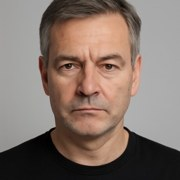
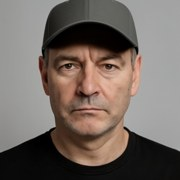
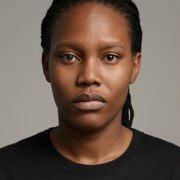
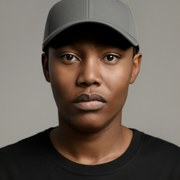
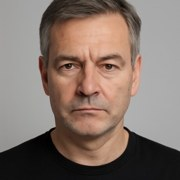
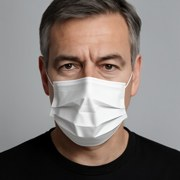
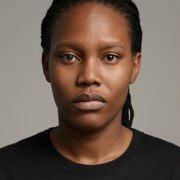
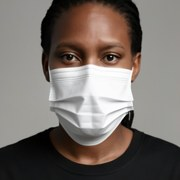
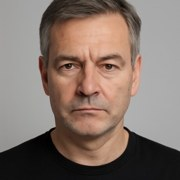
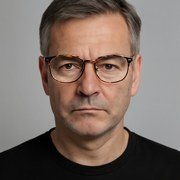
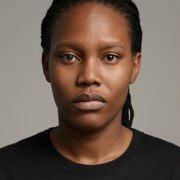
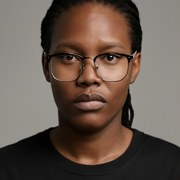

Selected HASH IDs: ['2499fb92d4f2ec71', '3ed74443144a664f']
Saved: /content/drive/.shortcut-targets-by-id/1PC3BlA0EHJknESqXxcHrKbm48XgVYJJD/Frugal AI Project/analysis_outputs/20261012T220605Z_c9b49572/21_image_metadata_examples.html


In [9]:
# Image and metadata examples only: no human-review information.

import base64
import html
from IPython.display import HTML, display

N_IDENTITIES = 2
EXAMPLE_SEED = 60
VERSIONS = ['cap', 'mask', 'glasses']


def image_data_uri(path, size=(180, 180)):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        image.thumbnail(size)

        buffer = io.BytesIO()
        image.save(buffer, format='JPEG', quality=88)

    encoded = base64.b64encode(buffer.getvalue()).decode('utf-8')
    return f'data:image/jpeg;base64,{encoded}'


def image_details(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)

        return {
            'width': image.width,
            'height': image.height,
            'mode': image.mode,
            'file_size_kib': path.stat().st_size / 1024,
        }


# Keep identities for which every available generated accessory exists.
generated_versions = [
    version for version in VERSIONS
    if version != 'original'
    and version in set(manifest.loc[manifest['exists'], 'accessory'])
]

complete_hashes = (
    manifest.loc[
        manifest['accessory'].isin(generated_versions)
        & manifest['exists'],
        ['HASH', 'accessory']
    ]
    .groupby('HASH')['accessory']
    .nunique()
)

complete_hashes = complete_hashes.loc[
    complete_hashes.eq(len(generated_versions))
].index.tolist()

complete_hashes = [
    hash_id for hash_id in complete_hashes
    if (SOURCE / f'{hash_id}.jpg').is_file()
]

if not complete_hashes:
    raise RuntimeError(
        'No sampled identities have all image versions available.'
    )

rng = np.random.default_rng(EXAMPLE_SEED)

selected_hashes = sorted(
    rng.choice(
        complete_hashes,
        size=min(N_IDENTITIES, len(complete_hashes)),
        replace=False
    ).tolist()
)

metadata = sample.loc[
    sample['HASH'].isin(selected_hashes)
].set_index('HASH')

generated_paths = (
    manifest.loc[
        manifest['HASH'].isin(selected_hashes)
        & manifest['exists'],
        ['HASH', 'accessory', 'path']
    ]
    .set_index(['HASH', 'accessory'])['path']
)


def path_for(hash_id, version):
    if version == 'original':
        return SOURCE / f'{hash_id}.jpg'

    return Path(generated_paths.loc[(hash_id, version)])


def version_table(version):
    rows = []

    for hash_id in selected_hashes:
        original_path = SOURCE / f'{hash_id}.jpg'
        generated_path = path_for(hash_id, version)

        original_details = image_details(original_path)
        generated_details = image_details(generated_path)
        meta = metadata.loc[hash_id]

        rows.append(f"""
        <tr>
          <td>
            <img src="{image_data_uri(original_path)}"
                 alt="Original portrait"
                 style="width:160px;height:160px;object-fit:contain;
                        background:#edf0ed;border-radius:8px;">
          </td>

          <td>
            <b>Filename:</b> {html.escape(original_path.name)}<br>
            <b>Dimensions:</b>
                {original_details['width']} × {original_details['height']} px<br>
            <b>Colour mode:</b> {original_details['mode']}<br>
            <b>File size:</b> {original_details['file_size_kib']:.1f} KiB
          </td>

          <td>
            <img src="{image_data_uri(generated_path)}"
                 alt="Generated {html.escape(version)} portrait"
                 style="width:160px;height:160px;object-fit:contain;
                        background:#edf0ed;border-radius:8px;">
          </td>

          <td>
            <b>Version:</b> {html.escape(version.title())}<br>
            <b>Filename:</b> {html.escape(generated_path.name)}<br>
            <b>Dimensions:</b>
                {generated_details['width']} × {generated_details['height']} px<br>
            <b>Colour mode:</b> {generated_details['mode']}<br>
            <b>File size:</b> {generated_details['file_size_kib']:.1f} KiB
          </td>

          <td>
            <b>HASH:</b> {html.escape(str(hash_id))}<br>
            <b>Ethnicity:</b> {html.escape(str(meta['ETHNICITY']))}<br>
            <b>Gender:</b> {html.escape(str(meta['GENDER']))}<br>
            <b>Age:</b> {html.escape(str(meta['AGE']))}
          </td>
        </tr>
        """)

    return f"""
    <h3>{html.escape(version.title())}: original versus generated</h3>
    <table>
      <thead>
        <tr>
          <th>Original portrait</th>
          <th>Original file information</th>
          <th>Generated portrait</th>
          <th>Generated file information</th>
          <th>Dataset metadata</th>
        </tr>
      </thead>
      <tbody>
        {''.join(rows)}
      </tbody>
    </table>
    """


display_page = f"""
<div class="image-metadata-examples">
<style>
.image-metadata-examples {{
  font-family: Arial, sans-serif;
  color: #20332e;
}}
.image-metadata-examples table {{
  border-collapse: collapse;
  width: 100%;
  margin: 8px 0 28px;
  font-size: 13px;
}}
.image-metadata-examples th,
.image-metadata-examples td {{
  border: 1px solid #d3ddd4;
  padding: 9px;
  vertical-align: top;
  text-align: left;
  line-height: 1.5;
}}
.image-metadata-examples th {{
  background: #e6f0e8;
}}
</style>

<h2>Original and generated portrait examples</h2>
<p>
The same {len(selected_hashes)} sampled identity/identities appear in every
table. This display contains image and dataset information only.
</p>

{''.join(version_table(version) for version in VERSIONS
         if version in generated_versions)}
</div>
"""

display(HTML(display_page))

(OUT / '21_image_metadata_examples.html').write_text(
    display_page,
    encoding='utf-8'
)

print('Selected HASH IDs:', selected_hashes)
print('Saved:', OUT / '21_image_metadata_examples.html')

## 4. Human review: progress and observed quality

Using combined team file: /content/drive/MyDrive/Frugal AI Project/Human-review/human_review/team_results/combined_human_review.csv
Combined reviews: 690
Distinct reviewers: 3


,reviewer,reviews
0,Salma,515
1,Nourou Dine,137
2,Mustapha,38


Review scope: ALL_TEAM
Selected reviews not linked to available generated outputs: 0


status,accessory,accept,reject,uncertain,unreviewed,available,reviewed,coverage_pct,acceptance_pct_of_reviewed
0,mask,270,2,31,417,720,303,42.1,89.1
1,cap,263,20,20,417,720,303,42.1,86.8
2,glasses,84,0,0,636,720,84,11.7,100.0


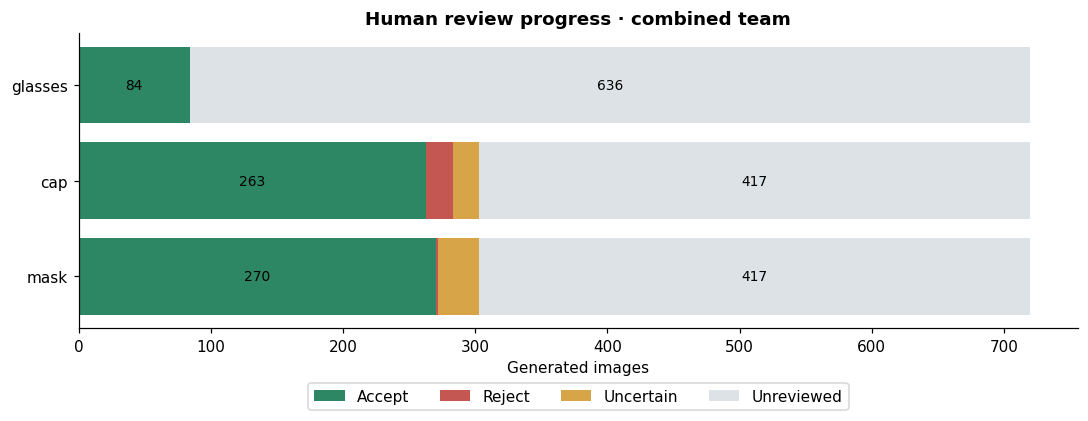

In [10]:
# Human-review statistics from the combined team CSV

review_columns = [
    'HASH', 'accessory', 'reviewer', 'decision', 'reviewed_at',
    'correct_accessory', 'placement_ok',
    'portrait_preserved', 'visual_defects', 'notes'
]

assert REVIEW_MODE in ['team', 'individual'], (
    "Set REVIEW_MODE to 'team' or 'individual'."
)

# Prefer the final combined file created by the team-review notebook.
combined_path = TEAM_DIR / 'combined_human_review.csv' if TEAM_DIR else None

if combined_path is not None and combined_path.is_file():
    review_files = [combined_path]
    print('Using combined team file:', combined_path)

elif REVIEW_CSV is not None and REVIEW_CSV.is_file():
    review_files = [REVIEW_CSV]
    print('Using review CSV:', REVIEW_CSV)

else:
    review_files = []
    print('No combined review CSV found yet.')

parts = []

for path in review_files:
    content = path.read_bytes()
    INPUT_HASHES[str(path)] = hashlib.sha256(content).hexdigest()

    frame = pd.read_csv(io.BytesIO(content), dtype=str).fillna('')

    missing_columns = set(review_columns) - set(frame.columns)
    assert not missing_columns, (
        f'{path.name} is missing columns: {sorted(missing_columns)}'
    )

    parts.append(frame[review_columns].copy())

raw_reviews = (
    pd.concat(parts, ignore_index=True)
    if parts else pd.DataFrame(columns=review_columns)
)

# Validate and keep the latest version if the same reviewer saved an item again.
if len(raw_reviews):
    assert raw_reviews.decision.isin(
        ['accept', 'reject', 'uncertain']
    ).all(), 'Unexpected decision value in the combined CSV.'

    raw_reviews['timestamp'] = pd.to_datetime(
        raw_reviews['reviewed_at'],
        utc=True,
        errors='coerce'
    )

    assert raw_reviews.timestamp.notna().all(), (
        'Some reviewed_at values cannot be read as timestamps.'
    )

    raw_reviews = (
        raw_reviews
        .sort_values('timestamp')
        .drop_duplicates(['HASH', 'accessory', 'reviewer'], keep='last')
        .copy()
    )

    # The team design gives one reviewer one assigned image/accessory pair.
    assert not raw_reviews.duplicated(['HASH', 'accessory']).any(), (
        'Duplicate decisions found for an image/accessory pair. '
        'Check the combined CSV before interpreting results.'
    )

    reviewer_counts = raw_reviews.groupby('reviewer').size().sort_values(
        ascending=False
    )

    print('Combined reviews:', len(raw_reviews))
    print('Distinct reviewers:', len(reviewer_counts))
    display(reviewer_counts.rename('reviews').reset_index())

    selected_reviewer = (
        'ALL_TEAM'
        if REVIEW_MODE == 'team'
        else (REVIEWER if REVIEWER is not None else reviewer_counts.index[0])
    )

    selected = (
        raw_reviews.copy()
        if REVIEW_MODE == 'team'
        else raw_reviews.loc[
            raw_reviews.reviewer.eq(selected_reviewer)
        ].copy()
    )

    print('Review scope:', selected_reviewer)

else:
    selected_reviewer = REVIEWER
    selected = raw_reviews.copy()
    print('No saved reviews yet.')

# Use only generated images that are physically available.
available = manifest.loc[manifest.exists].copy()
available_accessories = [
    accessory for accessory in ACCESSORY_DIRS
    if accessory in set(available.accessory)
]

# Check whether every review corresponds to an available generated image.
unmatched = selected.merge(
    available[['HASH', 'accessory']],
    on=['HASH', 'accessory'],
    how='left',
    indicator=True
)

print(
    'Selected reviews not linked to available generated outputs:',
    int(unmatched['_merge'].eq('left_only').sum())
)

# Join the reviews to source metadata and generation availability.
reviewed = available.merge(
    selected[review_columns],
    on=['HASH', 'accessory'],
    how='left',
    validate='one_to_one'
)

reviewed['status'] = reviewed['decision'].fillna('unreviewed')

statuses = ['accept', 'reject', 'uncertain', 'unreviewed']

progress = (
    pd.crosstab(reviewed['accessory'], reviewed['status'])
    .reindex(
        index=available_accessories,
        columns=statuses,
        fill_value=0
    )
)

progress['available'] = progress[statuses].sum(axis=1)
progress['reviewed'] = progress[
    ['accept', 'reject', 'uncertain']
].sum(axis=1)

progress['coverage_pct'] = (
    100 * progress['reviewed'] /
    progress['available'].replace(0, np.nan)
)

progress['acceptance_pct_of_reviewed'] = (
    100 * progress['accept'] /
    progress['reviewed'].replace(0, np.nan)
)

table(progress.round(1).reset_index(), '12_review_progress')

fig, ax = plt.subplots(figsize=(10, 4))

left = np.zeros(len(progress))

for status in statuses:
    bars = ax.barh(
        progress.index,
        progress[status],
        left=left,
        color=COLORS[status],
        label=status.title()
    )

    for bar, value in zip(bars, progress[status]):
        if value >= max(1, progress.available.max() * 0.045):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                str(value),
                ha='center',
                va='center',
                fontsize=9
            )

    left += progress[status].to_numpy()

scope_name = (
    'combined team'
    if REVIEW_MODE == 'team'
    else f'reviewer: {selected_reviewer}'
)

ax.set(
    xlabel='Generated images',
    title=f'Human review progress · {scope_name}'
)

ax.legend(
    ncol=4,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16)
)

fig.tight_layout()
finish('13_review_progress')

,accessory,reviewed_n,accepted_n,acceptance_rate,wilson_95_low,wilson_95_high
0,mask,303,270,0.891,0.851,0.921
1,cap,303,263,0.868,0.825,0.902
2,glasses,84,84,1.000,0.956,1.000


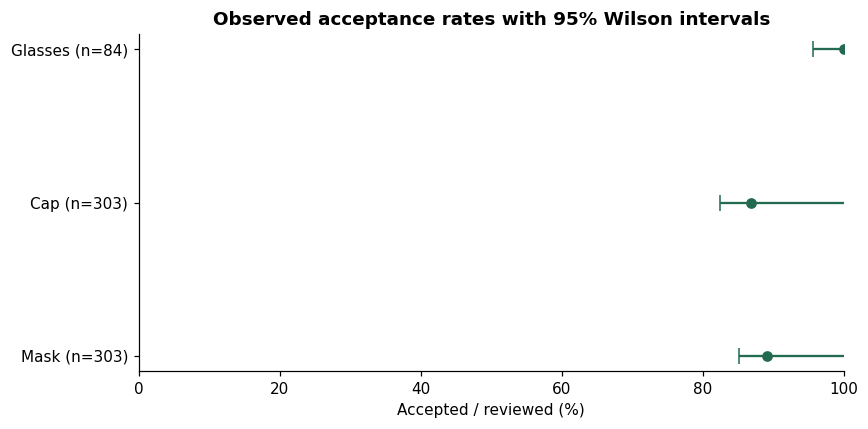

,accessory,check,answered_n,issue_n,uncertain_n,missing_or_invalid_n
0,mask,Wrong accessory,303,0,0,0
1,mask,Placement issue,303,22,3,0
2,mask,Preservation issue,303,1,0,0
3,mask,Visual defect,303,7,3,0
4,cap,Wrong accessory,303,0,0,0
5,cap,Placement issue,303,6,1,0
6,cap,Preservation issue,303,28,1,0
7,cap,Visual defect,303,21,2,0
8,glasses,Wrong accessory,84,0,0,0
9,glasses,Placement issue,84,0,0,0


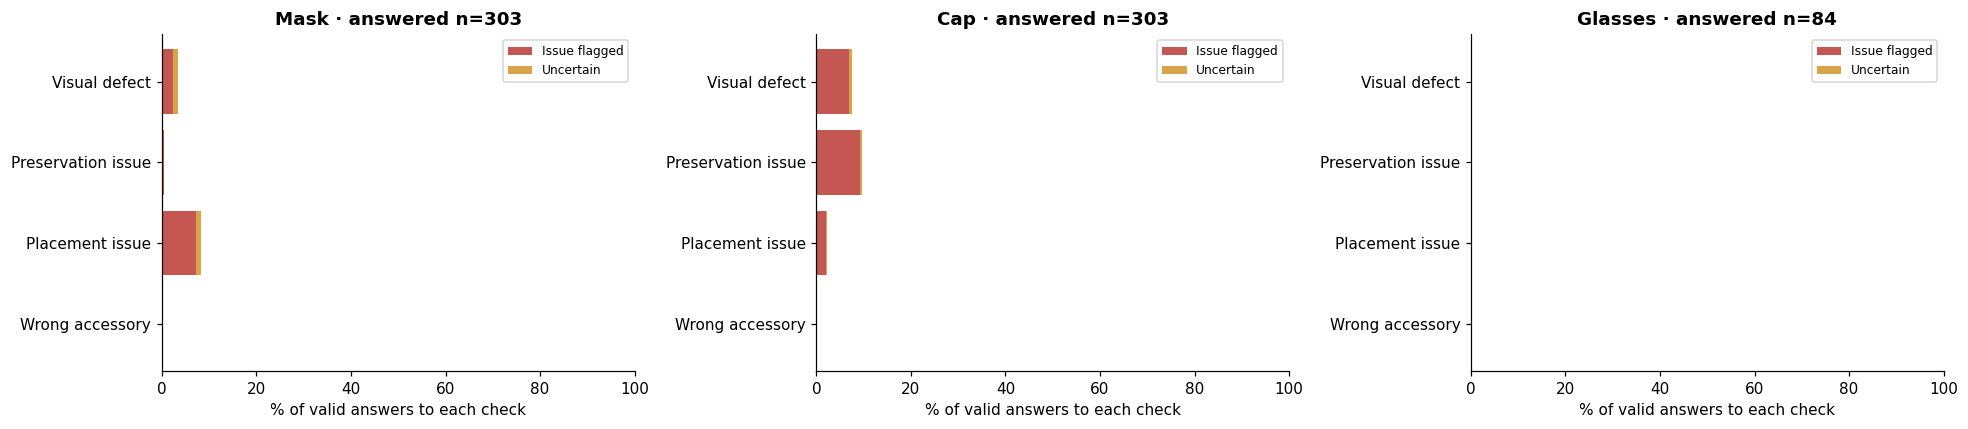

In [11]:
# Wilson intervals describe binomial sampling uncertainty.
# They do not measure reviewer agreement or selection bias.

def wilson(k, n):
    if n == 0:
        return np.nan, np.nan

    z = 1.96
    p = k / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half = (
        z * math.sqrt(
            p * (1 - p) / n +
            z**2 / (4 * n**2)
        ) / denominator
    )

    return center - half, center + half


# Acceptance-rate table and confidence intervals
quality_rows = []

for accessory, row in progress.iterrows():
    lo, hi = wilson(row['accept'], row['reviewed'])

    quality_rows.append({
        'accessory': accessory,
        'reviewed_n': int(row['reviewed']),
        'accepted_n': int(row['accept']),
        'acceptance_rate': (
            row['accept'] / row['reviewed']
            if row['reviewed'] else np.nan
        ),
        'wilson_95_low': lo,
        'wilson_95_high': hi,
    })

quality = pd.DataFrame(quality_rows)
table(quality.round(3), '14_acceptance_rates')

with_reviews = quality.loc[quality['reviewed_n'].gt(0)].copy()

if len(with_reviews):
    fig, ax = plt.subplots(figsize=(8, 4))

    rates = with_reviews['acceptance_rate'].to_numpy() * 100
    lower_errors = rates - with_reviews['wilson_95_low'].to_numpy() * 100
    upper_errors = with_reviews['wilson_95_high'].to_numpy() * 100

    ax.errorbar(
        rates,
        np.arange(len(with_reviews)),
        xerr=np.vstack([lower_errors, upper_errors]),
        fmt='o',
        color=COLORS['sample'],
        capsize=5
    )

    ax.set_yticks(
        np.arange(len(with_reviews)),
        [
            f'{row.accessory.title()} (n={row.reviewed_n})'
            for row in with_reviews.itertuples()
        ]
    )

    ax.set(
        xlim=(0, 100),
        xlabel='Accepted / reviewed (%)',
        title='Observed acceptance rates with 95% Wilson intervals'
    )

    fig.tight_layout()
    finish('15_acceptance_intervals')

else:
    print('Acceptance plot skipped: no saved reviews.')


# Counts of problems reported in each review check
checks = {
    'correct_accessory': ('Wrong accessory', 'no'),
    'placement_ok': ('Placement issue', 'no'),
    'portrait_preserved': ('Preservation issue', 'no'),
    'visual_defects': ('Visual defect', 'yes'),
}

check_rows = []

for accessory in available_accessories:
    subset = reviewed.loc[
        reviewed['accessory'].eq(accessory)
        & reviewed['decision'].notna()
    ].copy()

    for column, (label, failure_value) in checks.items():
        valid = subset[column].isin(['yes', 'no', 'uncertain'])
        answered_n = int(valid.sum())

        check_rows.append({
            'accessory': accessory,
            'check': label,
            'answered_n': answered_n,
            'issue_n': int(subset[column].eq(failure_value).sum()),
            'uncertain_n': int(subset[column].eq('uncertain').sum()),
            'missing_or_invalid_n': int((~valid).sum()),
        })

check_summary = pd.DataFrame(check_rows)
table(check_summary, '16_review_issue_counts')


# Plot issue and uncertainty percentages per review question
if reviewed['decision'].notna().any():
    fig, axes = plt.subplots(
        1,
        len(available_accessories),
        figsize=(6 * len(available_accessories), 4),
        squeeze=False
    )

    for ax, accessory in zip(axes.flat, available_accessories):
        subset = check_summary.loc[
            check_summary['accessory'].eq(accessory)
        ].copy()

        denominator = subset['answered_n'].replace(0, np.nan)
        issue_pct = 100 * subset['issue_n'] / denominator
        uncertain_pct = 100 * subset['uncertain_n'] / denominator

        ax.barh(
            subset['check'],
            issue_pct.fillna(0),
            color=COLORS['reject'],
            label='Issue flagged'
        )

        ax.barh(
            subset['check'],
            uncertain_pct.fillna(0),
            left=issue_pct.fillna(0),
            color=COLORS['uncertain'],
            label='Uncertain'
        )

        ax.set(
            xlim=(0, 100),
            xlabel='% of valid answers to each check',
            title=(
                f'{accessory.title()} · '
                f'answered n={int(subset["answered_n"].max())}'
            )
        )

        ax.legend(fontsize=8)

    fig.tight_layout()
    finish('17_review_issues')

else:
    print('Issue plot skipped: no saved reviews.')

### Review coverage and acceptance by demographic cell

,ETHNICITY,GENDER,AGE,accessory,generated_n,reviewed_n,accepted_n,coverage_pct,acceptance_pct
0,African,Female,25,cap,30,30,22,100.0,73.3
1,African,Female,25,glasses,30,10,10,33.3,100.0
2,African,Female,25,mask,30,30,22,100.0,73.3
3,African,Female,40,cap,30,30,23,100.0,76.7
4,African,Female,40,glasses,30,10,10,33.3,100.0
...,...,...,...,...,...,...,...,...,...
67,Indian,Male,40,glasses,30,0,0,0.0,NaN
68,Indian,Male,40,mask,30,0,0,0.0,NaN
69,Indian,Male,55,cap,30,0,0,0.0,NaN
70,Indian,Male,55,glasses,30,0,0,0.0,NaN


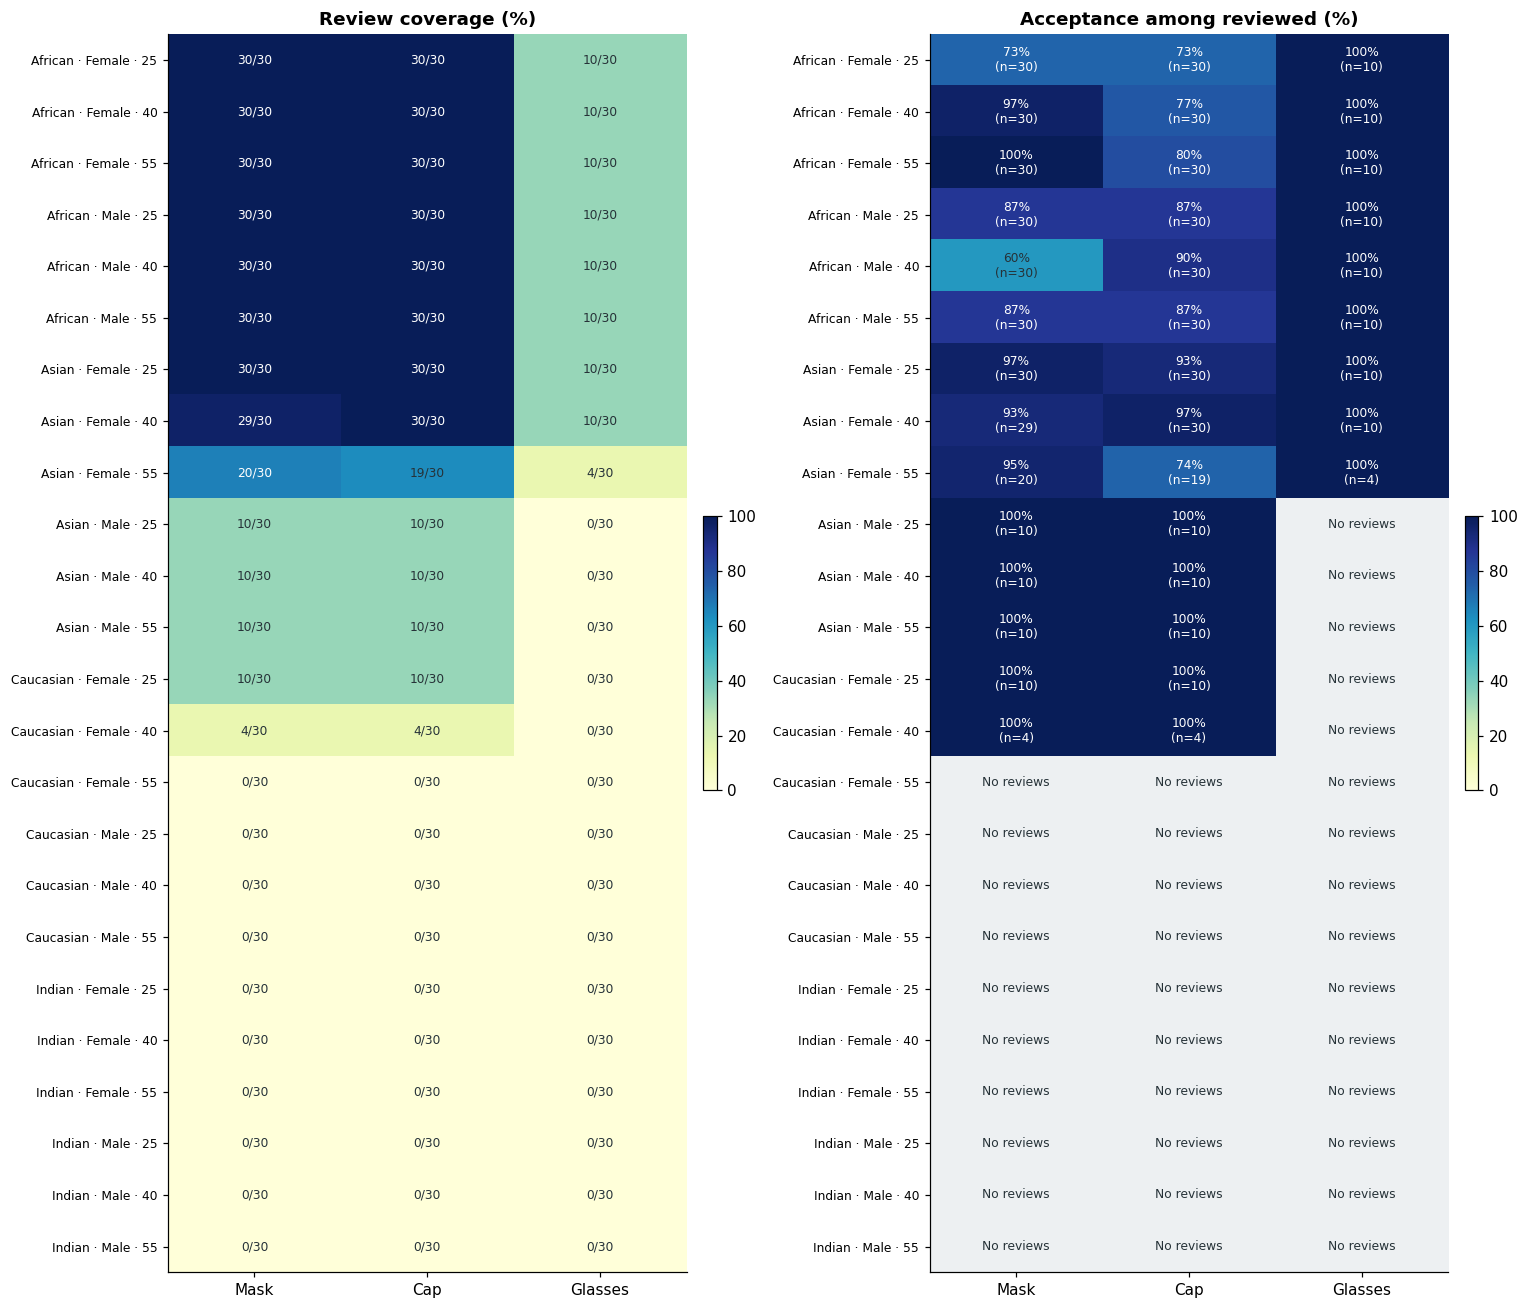

In [12]:
# Review coverage and acceptance rate by demographic group and accessory

group_rows = []

for keys, group in reviewed.groupby(DEMOGRAPHICS + ['accessory']):
    generated_n = len(group)
    reviewed_n = int(group['decision'].notna().sum())
    accepted_n = int(group['decision'].eq('accept').sum())

    group_rows.append({
        **dict(zip(DEMOGRAPHICS + ['accessory'], keys)),
        'generated_n': generated_n,
        'reviewed_n': reviewed_n,
        'accepted_n': accepted_n,
        'coverage_pct': (
            100 * reviewed_n / generated_n
            if generated_n else np.nan
        ),
        'acceptance_pct': (
            100 * accepted_n / reviewed_n
            if reviewed_n else np.nan
        ),
    })

group_summary = pd.DataFrame(group_rows)

table(
    group_summary.round(1),
    '18_review_demographic_cells'
)

if len(group_summary):
    group_summary['cell'] = group_summary[DEMOGRAPHICS].astype(str).agg(
        ' · '.join,
        axis=1
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 12))

    metrics = [
        ('coverage_pct', 'Review coverage (%)'),
        ('acceptance_pct', 'Acceptance among reviewed (%)'),
    ]

    keyed = group_summary.set_index(['cell', 'accessory'])

    for ax, (metric, title) in zip(axes, metrics):
        pivot = (
            group_summary
            .pivot(index='cell', columns='accessory', values=metric)
            .reindex(columns=available_accessories)
        )

        cmap = plt.get_cmap('YlGnBu').copy()
        cmap.set_bad('#edf0f2')

        plot = ax.imshow(
            pivot.to_numpy(dtype=float),
            vmin=0,
            vmax=100,
            cmap=cmap,
            aspect='auto'
        )

        ax.set_xticks(
            np.arange(len(pivot.columns)),
            pivot.columns.str.title()
        )

        ax.set_yticks(
            np.arange(len(pivot.index)),
            pivot.index,
            fontsize=8
        )

        ax.set_title(title)

        for y, cell in enumerate(pivot.index):
            for x, accessory in enumerate(pivot.columns):
                row = keyed.loc[(cell, accessory)]
                value = row[metric]

                if metric == 'coverage_pct':
                    label = f'{row.reviewed_n}/{row.generated_n}'
                elif pd.notna(value):
                    label = f'{value:.0f}%\n(n={row.reviewed_n})'
                else:
                    label = 'No reviews'

                text_color = (
                    'white'
                    if pd.notna(value) and value > 65
                    else '#263238'
                )

                ax.text(
                    x, y, label,
                    ha='center',
                    va='center',
                    fontsize=8,
                    color=text_color
                )

        fig.colorbar(plot, ax=ax, fraction=0.025, pad=0.03)

    fig.tight_layout()
    finish('19_review_demographic_heatmaps')

else:
    print('Demographic heatmaps skipped: no generated images were available.')

### Review coverage and acceptance rate

- **coverage_pct**: How much of a demographic group has been reviewed.

$$
\text{coverage_pct} =
\frac{\text{reviewed images}}{\text{generated images available}} \times 100
$$

Example: if 18 of 30 generated glasses images for Asian–Female–25 were reviewed:

$$
18 / 30 = 60\%
$$

- **acceptance_pct**: Among images that were reviewed, how many were accepted.

$$
\text{acceptance_pct} =
\frac{\text{accepted images}}{\text{reviewed images}} \times 100
$$

Example: if 18 images were reviewed and 15 were accepted:

$$
15 / 18 = 83.3\%
$$

Coverage shows how complete the human review is. Acceptance shows how successful the generated images were among completed reviews.

## 5. Interpretation and reproducibility


In [13]:
provenance = {
    'executed_at_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'seed': SEED,
    'selected_reviewer': selected_reviewer,
    'review_mode': REVIEW_MODE,
    'inputs': INPUT_HASHES,
    'versions': {
        'pandas': pd.__version__,
        'numpy': np.__version__,
    },
    'original_records': len(original),
    'sample_records': len(sample),
    'generated_matched': int(manifest['exists'].sum()),
    'reviewed_matched_selected_scope': int(
        reviewed['decision'].notna().sum()
    ),
}

(OUT / 'analysis_provenance.json').write_text(
    json.dumps(provenance, indent=2),
    encoding='utf-8'
)

display(Markdown(f"""
### Current snapshot

- **{len(original):,}** original metadata records; **{len(sample):,}** sampled identities.
- **{int(manifest['exists'].sum()):,}** available full-batch accessory edits matched to the sample.
- **{int(reviewed['decision'].notna().sum()):,}** matched saved assessments in the selected review scope (`{REVIEW_MODE}`).
- **{int(image_info['error'].ne('').sum()):,}** decoding or access failures in the scanned sample and outputs.

All figures, tables, and `analysis_provenance.json` were saved to:

`{OUT}`

Rerun the notebook to refresh the results after more reviews are completed.
"""))


### Current snapshot

- **9,000** original metadata records; **720** sampled identities.
- **2,160** available full-batch accessory edits matched to the sample.
- **690** matched saved assessments in the selected review scope (`team`).
- **0** decoding or access failures in the scanned sample and outputs.

All figures, tables, and `analysis_provenance.json` were saved to:

`/content/drive/.shortcut-targets-by-id/1PC3BlA0EHJknESqXxcHrKbm48XgVYJJD/Frugal AI Project/analysis_outputs/20261012T220605Z_c9b49572`

Rerun the notebook to refresh the results after more reviews are completed.


Review status,Original portrait,Generated portrait,Original metadata,Human review,Reviewer notes
Accepted,,,HASH: 1144d677f2b9c323 Ethnicity: African Gender: Female Age: 55,Decision: accept Accessory present: yes Placement natural: yes Portrait preserved: yes Visual defects: no Reviewer: Salma,No note provided.
Rejected,,,HASH: a6bb26ddd400f455 Ethnicity: African Gender: Female Age: 40,Decision: reject Accessory present: yes Placement natural: yes Portrait preserved: no Visual defects: no Reviewer: Salma,The hair disappeared
Uncertain,,,HASH: 70a05213760d6f33 Ethnicity: African Gender: Male Age: 25,Decision: uncertain Accessory present: yes Placement natural: yes Portrait preserved: no Visual defects: no Reviewer: Salma,Hair color changed
Review status,Original portrait,Generated portrait,Original metadata,Human review,Reviewer notes
Accepted,,,HASH: ecb6624f92a702c6 Ethnicity: African Gender: Female Age: 25,Decision: accept Accessory present: yes Placement natural: yes Portrait preserved: yes Visual defects: no Reviewer: Salma,No note provided.
Rejected,,,HASH: 3b542cf5db7c1f9d Ethnicity: African Gender: Male Age: 25,Decision: reject Accessory present: yes Placement natural: no Portrait preserved: yes Visual defects: yes Reviewer: Salma,"The mask straps should go behind the ears, not inside the ears."
Uncertain,,,HASH: 32869acca12095f7 Ethnicity: African Gender: Female Age: 25,Decision: uncertain Accessory present: yes Placement natural: no Portrait preserved: yes Visual defects: no Reviewer: Salma,"The mask straps should go behind the ears, not inside the ears."
Review status,Original portrait,Generated portrait,Original metadata,Human review,Reviewer notes
Accepted,,,HASH: 6f9a2746e2f9707b Ethnicity: Asian Gender: Female Age: 55,Decision: accept Accessory present: yes Placement natural: yes Portrait preserved: yes Visual defects: no Reviewer: Salma,No note provided.

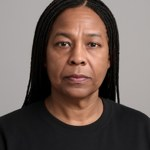
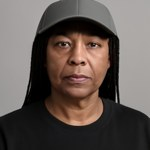
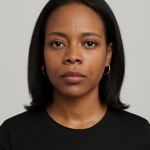
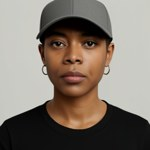
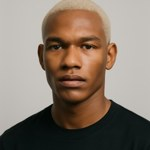
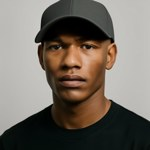
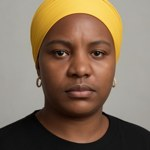
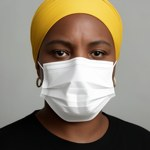
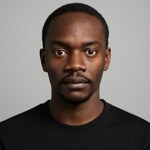
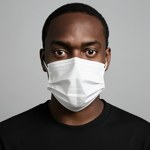
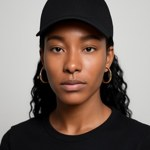
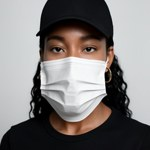
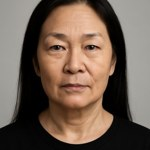
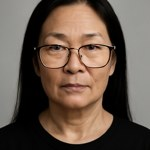

Saved: /content/drive/.shortcut-targets-by-id/1PC3BlA0EHJknESqXxcHrKbm48XgVYJJD/Frugal AI Project/analysis_outputs/20261012T220605Z_c9b49572/20_qualitative_examples_by_status.html


In [14]:
# Qualitative examples selected by human-review status.
# Each row shows: original portrait, generated portrait, metadata, review, and notes.

import base64
import html
from IPython.display import HTML, display

STATUSES = ['accept', 'reject', 'uncertain']

STATUS_LABELS = {
    'accept': 'Accepted',
    'reject': 'Rejected',
    'uncertain': 'Uncertain'
}

EXAMPLE_SEED = 60

GENERATED_VERSIONS = [
    accessory for accessory in ['cap', 'mask', 'glasses']
    if accessory in available_accessories
]


def thumbnail_data_uri(path, size=(150, 150)):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        image.thumbnail(size)

        buffer = io.BytesIO()
        image.save(buffer, format='JPEG', quality=88)

    return (
        'data:image/jpeg;base64,' +
        base64.b64encode(buffer.getvalue()).decode('utf-8')
    )


def show_value(value, default='Not reviewed'):
    if pd.isna(value) or str(value).strip() == '':
        return default
    return html.escape(str(value))


# Pick one random example for every available status in every accessory.
rng = np.random.default_rng(EXAMPLE_SEED)
selected_examples = {}

for accessory in GENERATED_VERSIONS:
    accessory_rows = reviewed.loc[
        reviewed['accessory'].eq(accessory)
    ].copy()

    accessory_rows['example_status'] = accessory_rows['decision'].fillna(
        'unreviewed'
    )

    chosen_rows = []

    for status in STATUSES:
        candidates = accessory_rows.loc[
            accessory_rows['example_status'].eq(status)
        ]

        if len(candidates):
            chosen_rows.append(
                candidates.iloc[rng.integers(0, len(candidates))]
            )

    selected_examples[accessory] = pd.DataFrame(chosen_rows)


def make_accessory_table(accessory):
    frame = selected_examples[accessory]

    if frame.empty:
        return f'<h3>{accessory.title()}</h3><p>No examples available.</p>'

    rows_html = []

    for _, row in frame.iterrows():
        hash_id = str(row['HASH'])

        original_path = SOURCE / f'{hash_id}.jpg'
        generated_path = Path(row['path'])

        original_uri = thumbnail_data_uri(original_path)
        generated_uri = thumbnail_data_uri(generated_path)

        status = row['example_status']
        note = show_value(row.get('notes', ''), default='No note provided.')

        rows_html.append(f"""
        <tr>
          <td><b>{STATUS_LABELS[status]}</b></td>

          <td>
            <img src="{original_uri}" alt="Original portrait"
                 style="width:150px;height:150px;object-fit:contain;
                        background:#edf0ed;border-radius:8px;">
          </td>

          <td>
            <img src="{generated_uri}" alt="Generated {accessory} portrait"
                 style="width:150px;height:150px;object-fit:contain;
                        background:#edf0ed;border-radius:8px;">
          </td>

          <td>
            <b>HASH:</b> {html.escape(hash_id)}<br>
            <b>Ethnicity:</b> {show_value(row['ETHNICITY'])}<br>
            <b>Gender:</b> {show_value(row['GENDER'])}<br>
            <b>Age:</b> {show_value(row['AGE'])}
          </td>

          <td>
            <b>Decision:</b> {show_value(row['decision'])}<br>
            <b>Accessory present:</b> {show_value(row['correct_accessory'])}<br>
            <b>Placement natural:</b> {show_value(row['placement_ok'])}<br>
            <b>Portrait preserved:</b> {show_value(row['portrait_preserved'])}<br>
            <b>Visual defects:</b> {show_value(row['visual_defects'])}<br>
            <b>Reviewer:</b> {show_value(row['reviewer'])}
          </td>

          <td style="max-width:260px; white-space:normal;">
            {note}
          </td>
        </tr>
        """)

    return f"""
    <h3>{accessory.title()} examples by review status</h3>

    <table>
      <thead>
        <tr>
          <th>Review status</th>
          <th>Original portrait</th>
          <th>Generated portrait</th>
          <th>Original metadata</th>
          <th>Human review</th>
          <th>Reviewer notes</th>
        </tr>
      </thead>
      <tbody>
        {''.join(rows_html)}
      </tbody>
    </table>
    """


page = f"""
<div class="qualitative-examples">
<style>
.qualitative-examples {{
  font-family: Arial, sans-serif;
  color: #20332e;
}}

.qualitative-examples table {{
  border-collapse: collapse;
  width: 100%;
  margin: 8px 0 30px;
  font-size: 12px;
}}

.qualitative-examples th,
.qualitative-examples td {{
  border: 1px solid #d3ddd4;
  padding: 8px;
  vertical-align: top;
  text-align: left;
  line-height: 1.45;
}}

.qualitative-examples th {{
  background: #e6f0e8;
}}
</style>

<h2>Qualitative examples: original and generated portraits</h2>

<p>
For each accessory, this table selects one available example of Accepted,
Rejected, Uncertain, and Not reviewed. Each generated image is shown beside
its original portrait. Reviewer notes are displayed when available.
</p>

{''.join(make_accessory_table(accessory)
         for accessory in GENERATED_VERSIONS)}
</div>
"""

display(HTML(page))

(OUT / '20_qualitative_examples_by_status.html').write_text(
    page,
    encoding='utf-8'
)

print('Saved:', OUT / '20_qualitative_examples_by_status.html')